# P2. Exploración de datos para la clasificación de riesgo en estaciones MiBici

## 1. Objetivo

El objetivo de esta exploración es comprender la estructura, calidad y comportamiento temporal de los datos de viajes de MiBici para evaluar la viabilidad de construir un modelo de clasificación relacionado con el riesgo operativo de las estaciones.

Debido a que los datos disponibles corresponden a registros de viajes y no a mediciones históricas directas de bicicletas disponibles o anclajes libres, el riesgo se analizará inicialmente mediante una variable proxy derivada del flujo de viajes. Por lo tanto, los resultados no deberán interpretarse como mediciones reales de disponibilidad de bicicletas.

## 2. Alcance de la exploración

En esta etapa se analizarán:

- La estructura y los tipos de datos.
- La cobertura temporal de los viajes.
- La presencia de valores nulos y registros duplicados.
- La distribución de los viajes por hora y día.
- Los flujos de salida y llegada por estación.
- La correspondencia entre los identificadores de estaciones y la nomenclatura disponible.

Los hallazgos permitirán definir las variables candidatas, la construcción de la variable objetivo y la estrategia de evaluación temporal del modelo.

## 3. Consideraciones metodológicas

- Se utilizarán únicamente variables necesarias para el análisis operativo.
- No se utilizarán identificadores de usuario, género ni año de nacimiento como variables predictoras.
- Las variables predictoras deberán construirse con información disponible antes del momento de predicción.
- La definición final del riesgo y sus umbrales se justificará con los resultados de la exploración.

In [1]:
from pathlib import Path
import sys

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

SEED = 42

print("Directorio de trabajo:", Path.cwd())
print("Python:", sys.version)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

Directorio de trabajo: /Users/edgargonzalezpaz/Documents/MLOps/TC5061-Proyecto-Equipo37/TC5061-Proyecto-Equipo37/notebooks
Python: 3.10.22 (main, Oct  1 2026, 20:08:28) [Clang 20.1.8 ]
Pandas: 2.3.3
NumPy: 2.2.6


In [2]:
import pandas as pd
from pathlib import Path

# Ruta al archivo original
ROOT = Path.cwd().parent
DATA_RAW = ROOT / "data" / "raw"

# Identificar el CSV
archivos_csv = list(DATA_RAW.glob("*.csv"))

if not archivos_csv:
    raise FileNotFoundError(f"No se encontraron archivos CSV en {DATA_RAW}")

if len(archivos_csv) > 1:
    raise ValueError(
        f"Se encontraron varios CSV. Selecciona explícitamente el archivo: {archivos_csv}"
    )

TRIPS_PATH = archivos_csv[0]

print(f"Archivo: {TRIPS_PATH.name}")
print(f"Tamaño: {TRIPS_PATH.stat().st_size / (1024**2):.2f} MB")
print("Cargando dataset...")

# Cargar las columnas necesarias para el análisis
trips = pd.read_csv(
    TRIPS_PATH,
    usecols=[
        "Inicio_del_viaje",
        "Fin_del_viaje",
        "Origen_Id",
        "Destino_Id",
    ],
    dtype={
        "Origen_Id": "Int32",
        "Destino_Id": "Int32",
    },
    parse_dates=[
        "Inicio_del_viaje",
        "Fin_del_viaje",
    ],
    low_memory=False,
)

print("\n¡Dataset cargado correctamente!")
print(f"Registros: {len(trips):,}")
print(f"Columnas: {len(trips.columns)}")
print(f"Memoria utilizada: {trips.memory_usage(deep=True).sum() / (1024**2):.2f} MB")

display(trips.head())

Archivo: mibici_2024_2025.csv
Tamaño: 627.61 MB
Cargando dataset...

¡Dataset cargado correctamente!
Registros: 9,177,953
Columnas: 4
Memoria utilizada: 227.57 MB


,Inicio_del_viaje,Fin_del_viaje,Origen_Id,Destino_Id
0,2024-01-01 00:05:25,2024-01-01 00:29:37,294,271
1,2024-01-01 00:07:23,2024-01-01 00:16:37,182,254
2,2024-01-01 00:07:31,2024-01-01 00:16:37,182,254
3,2024-01-01 00:07:56,2024-01-01 00:31:51,35,154
4,2024-01-01 00:08:09,2024-01-01 00:31:51,35,154


In [3]:
# 1. Dimensiones del dataset
print("Dimensiones del dataset:", trips.shape)

# 2. Tipos de datos
print("\nTipos de datos:")
display(trips.dtypes.to_frame("tipo_dato"))

# 3. Valores nulos
print("\nValores nulos:")
display(
    trips.isna().sum()
    .to_frame("valores_nulos")
    .assign(
        porcentaje=lambda df: (
            df["valores_nulos"] / len(trips) * 100
        ).round(2)
    )
)

# 4. Estadísticas descriptivas
print("\nEstadísticas descriptivas:")
display(trips.describe(include="all"))

# 5. Primeras y últimas filas
print("\nPrimeras filas:")
display(trips.head())

print("\nÚltimas filas:")
display(trips.tail())

Dimensiones del dataset: (9177953, 4)

Tipos de datos:


,tipo_dato
Inicio_del_viaje,datetime64[ns]
Fin_del_viaje,datetime64[ns]
Origen_Id,Int32
Destino_Id,Int32



Valores nulos:


,valores_nulos,porcentaje
Inicio_del_viaje,0,0.0
Fin_del_viaje,0,0.0
Origen_Id,0,0.0
Destino_Id,0,0.0



Estadísticas descriptivas:


,Inicio_del_viaje,Fin_del_viaje,Origen_Id,Destino_Id
count,9177953,9177953,9177953.0,9177953.0
mean,2024-12-27 16:16:44.491476224,2024-12-27 16:27:50.487806976,153.297274,155.039985
min,2024-01-01 00:05:25,2024-01-01 00:16:37,2.0,2.0
25%,2024-06-26 08:45:23,2024-06-26 08:55:31,51.0,51.0
50%,2024-12-24 10:58:30,2024-12-24 11:08:06,156.0,155.0
75%,2025-06-27 11:45:55,2025-06-27 11:56:33,255.0,260.0
max,2025-12-31 23:59:08,2026-01-01 00:09:47,402.0,402.0
std,NaN,NaN,111.215238,114.364563



Primeras filas:


,Inicio_del_viaje,Fin_del_viaje,Origen_Id,Destino_Id
0,2024-01-01 00:05:25,2024-01-01 00:29:37,294,271
1,2024-01-01 00:07:23,2024-01-01 00:16:37,182,254
2,2024-01-01 00:07:31,2024-01-01 00:16:37,182,254
3,2024-01-01 00:07:56,2024-01-01 00:31:51,35,154
4,2024-01-01 00:08:09,2024-01-01 00:31:51,35,154



Últimas filas:


,Inicio_del_viaje,Fin_del_viaje,Origen_Id,Destino_Id
9177948,2025-12-31 23:55:18,2025-12-31 23:55:58,178,178
9177949,2025-12-31 23:55:41,2026-01-01 00:01:43,333,337
9177950,2025-12-31 23:56:54,2026-01-01 00:09:47,178,371
9177951,2025-12-31 23:58:23,2026-01-01 00:08:42,205,209
9177952,2025-12-31 23:59:08,2025-12-31 23:59:10,52,260


In [4]:

# 1. Rango real de fechas
print("Primer inicio:", trips["Inicio_del_viaje"].min())
print("Último inicio:", trips["Inicio_del_viaje"].max())
print("Último fin:", trips["Fin_del_viaje"].max())

# 2. Duración de cada viaje en minutos
duracion_min = (
    trips["Fin_del_viaje"] - trips["Inicio_del_viaje"]
).dt.total_seconds() / 60

print("\nResumen de duración (minutos):")
display(duracion_min.describe(percentiles=[0.01, 0.25, 0.50, 0.75, 0.95, 0.99]).to_frame("duracion_min"))

# 3. Casos que requieren revisión
print("\nViajes con duración cero o negativa:", (duracion_min <= 0).sum())
print("Viajes de más de 180 minutos:", (duracion_min > 180).sum())

# 4. Viajes que comienzan en 2025 y terminan en 2026
cruzan_periodo = (
    (trips["Inicio_del_viaje"] <= "2025-12-31 23:59:59")
    & (trips["Fin_del_viaje"] >= "2026-01-01")
)

print("Viajes que cruzan a 2026:", cruzan_periodo.sum())

# 5. Registros con origen y destino iguales
print(
    "Viajes con origen igual a destino:",
    (trips["Origen_Id"] == trips["Destino_Id"]).sum()
)


Primer inicio: 2024-01-01 00:05:25
Último inicio: 2025-12-31 23:59:08
Último fin: 2026-01-01 00:09:47

Resumen de duración (minutos):


,duracion_min
count,9.177953e+06
mean,1.109994e+01
std,1.002753e+01
min,0.000000e+00
1%,2.166667e-01
25%,5.850000e+00
50%,9.566667e+00
75%,1.493333e+01
95%,2.421667e+01
99%,3.283333e+01



Viajes con duración cero o negativa: 23630
Viajes de más de 180 minutos: 991
Viajes que cruzan a 2026: 7
Viajes con origen igual a destino: 555621


In [5]:

from MiBici.features import filter_valid_trips

# Registrar el tamaño original
n_original = len(trips)

# Aplicar los criterios compartidos de limpieza
trips_limpios = filter_valid_trips(
    trips,
    min_min=1,
    max_min=180,
    drop_round_trips=True
)

# Resumen de resultados
n_limpios = len(trips_limpios)
n_excluidos = n_original - n_limpios
pct_conservado = n_limpios / n_original * 100
pct_excluido = n_excluidos / n_original * 100

print("RESUMEN DEL PREPROCESAMIENTO")
print("-" * 40)
print(f"Viajes originales:       {n_original:,}")
print(f"Viajes conservados:      {n_limpios:,}")
print(f"Viajes excluidos:        {n_excluidos:,}")
print(f"Porcentaje conservado:   {pct_conservado:.2f}%")
print(f"Porcentaje excluido:     {pct_excluido:.2f}%")

print("\nPrimeras filas del conjunto limpio:")
display(trips_limpios.head())

print("\nResumen de duración (minutos):")
display(trips_limpios["duracion_min"].describe())


2026-10-17 22:16:33.059 | INFO     | MiBici.config:<module>:11 - PROJ_ROOT path is: /Users/edgargonzalezpaz/Documents/MLOps/TC5061-Proyecto-Equipo37/TC5061-Proyecto-Equipo37


RESUMEN DEL PREPROCESAMIENTO
----------------------------------------
Viajes originales:       9,177,953
Viajes conservados:      8,600,822
Viajes excluidos:        577,131
Porcentaje conservado:   93.71%
Porcentaje excluido:     6.29%

Primeras filas del conjunto limpio:


,Inicio_del_viaje,Fin_del_viaje,Origen_Id,Destino_Id,duracion_min
0,2024-01-01 00:05:25,2024-01-01 00:29:37,294,271,24.200000
1,2024-01-01 00:07:23,2024-01-01 00:16:37,182,254,9.233333
2,2024-01-01 00:07:31,2024-01-01 00:16:37,182,254,9.100000
3,2024-01-01 00:07:56,2024-01-01 00:31:51,35,154,23.916667
4,2024-01-01 00:08:09,2024-01-01 00:31:51,35,154,23.700000



Resumen de duración (minutos):


count    8.600822e+06
mean     1.130018e+01
std      7.089145e+00
min      1.016667e+00
25%      6.083333e+00
50%      9.766667e+00
75%      1.500000e+01
max      1.799167e+02
Name: duracion_min, dtype: float64

Resumen de viajes diarios:


count      731.000000
mean     11765.830369
std       2759.619500
min       2586.000000
25%       9031.000000
50%      12927.000000
75%      14164.500000
max      15582.000000
Name: numero_viajes, dtype: float64

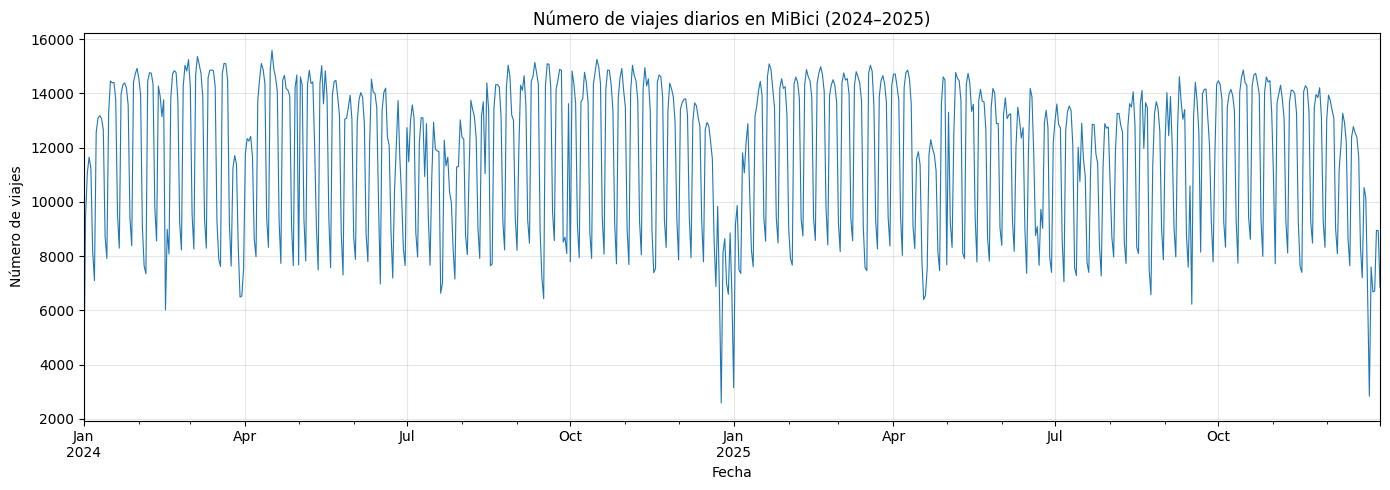

In [10]:
# Agregar viajes por fecha de inicio
viajes_diarios = (
    trips_limpios
    .assign(fecha=trips_limpios["Inicio_del_viaje"].dt.date)
    .groupby("fecha")
    .size()
    .rename("numero_viajes")
)

# Estadísticas descriptivas
print("Resumen de viajes diarios:")
display(viajes_diarios.describe())

# Visualización de la serie temporal
plt.figure(figsize=(14, 5))
viajes_diarios.index = pd.to_datetime(viajes_diarios.index)
viajes_diarios.plot(linewidth=0.8)

plt.title("Número de viajes diarios en MiBici (2024–2025)")
plt.xlabel("Fecha")
plt.ylabel("Número de viajes")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


,Promedio,Mediana,Desviación estándar,Días observados
Lunes,12513.37,13230.0,2143.32,105
Martes,13495.46,14146.0,1886.75,105
Miércoles,13476.98,14115.0,2118.03,105
Jueves,13377.45,13992.0,1871.62,104
Viernes,12686.92,13256.0,1748.11,104
Sábado,8929.80,9105.0,818.00,104
Domingo,7840.56,7883.0,470.73,104


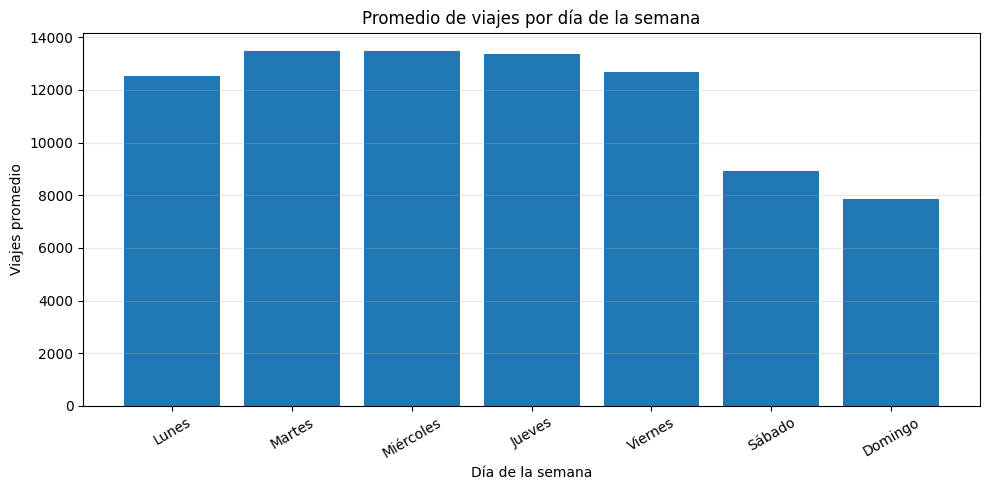

In [ ]:
# Agregar viajes por fecha
viajes_diarios = (
    trips_limpios
    .assign(fecha=trips_limpios["Inicio_del_viaje"].dt.normalize())
    .groupby("fecha")
    .size()
    .rename("numero_viajes")
    .reset_index()
)

# Día de la semana: lunes = 0, domingo = 6
nombres_dias = [
    "Lunes", "Martes", "Miércoles", "Jueves",
    "Viernes", "Sábado", "Domingo"
]

viajes_diarios["dia_semana"] = (
    viajes_diarios["fecha"].dt.dayofweek
)

resumen_semanal = (
    viajes_diarios
    .groupby("dia_semana")["numero_viajes"]
    .agg(["mean", "median", "std", "count"])
    .reindex(range(7))
)

resumen_semanal.index = nombres_dias
resumen_semanal.columns = [
    "Promedio", "Mediana", "Desviación estándar", "Días observados"
]

display(resumen_semanal.round(2))

# Visualizar el promedio por día
plt.figure(figsize=(10, 5))
plt.bar(resumen_semanal.index, resumen_semanal["Promedio"])
plt.title("Promedio de viajes por día de la semana")
plt.xlabel("Día de la semana")
plt.ylabel("Viajes promedio")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


,numero_viajes
mes,
2024-01-01,363362
2024-02-01,356050
2024-03-01,361064
2024-04-01,375368
2024-05-01,381745
2024-06-01,341877
2024-07-01,339844
2024-08-01,369650
2024-09-01,364497


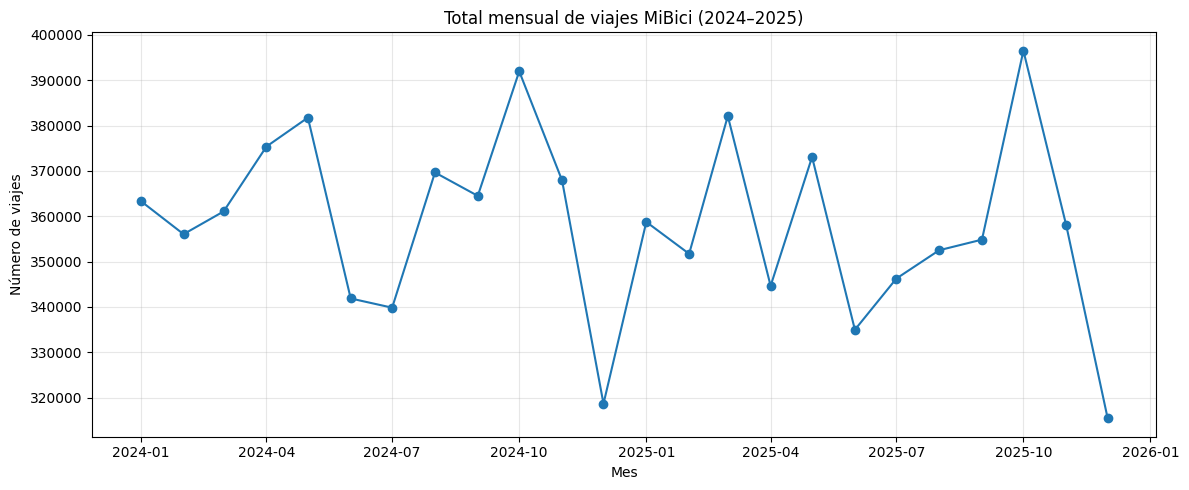

In [11]:
# Agregar el volumen por mes
viajes_mensuales = (
    trips_limpios
    .assign(
        mes=trips_limpios["Inicio_del_viaje"].dt.to_period("M")
    )
    .groupby("mes")
    .size()
    .rename("numero_viajes")
    .to_frame()
)

viajes_mensuales.index = viajes_mensuales.index.to_timestamp()

display(viajes_mensuales)

# Gráfica del total mensual
plt.figure(figsize=(12, 5))
plt.plot(
    viajes_mensuales.index,
    viajes_mensuales["numero_viajes"],
    marker="o"
)
plt.title("Total mensual de viajes MiBici (2024–2025)")
plt.xlabel("Mes")
plt.ylabel("Número de viajes")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


,numero_viajes
mes,
2024-01-01,363362
2024-02-01,356050
2024-03-01,361064
2024-04-01,375368
2024-05-01,381745
2024-06-01,341877
2024-07-01,339844
2024-08-01,369650
2024-09-01,364497


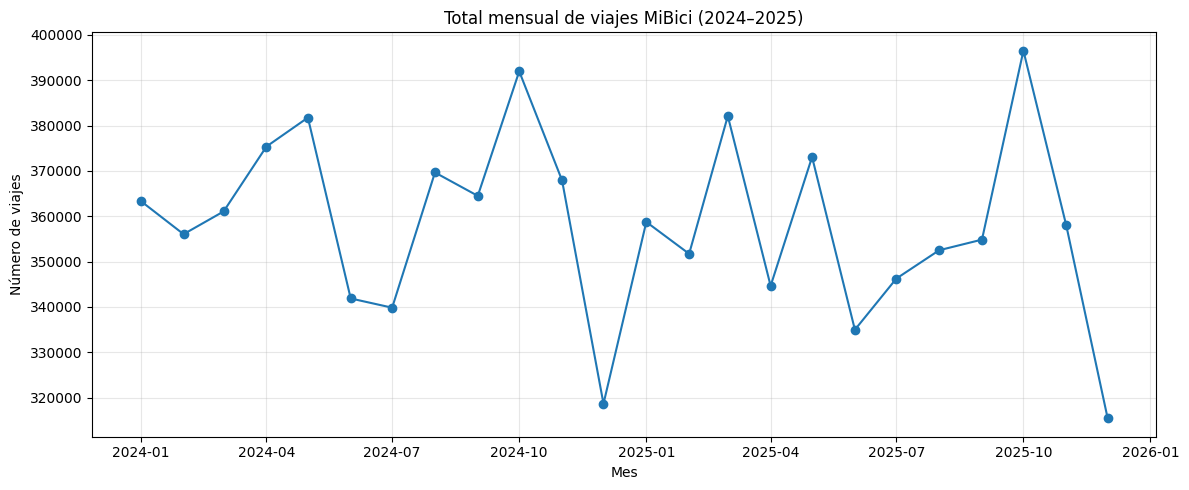

In [9]:

# Agregar el volumen por mes
viajes_mensuales = (
    trips_limpios
    .assign(
        mes=trips_limpios["Inicio_del_viaje"].dt.to_period("M")
    )
    .groupby("mes")
    .size()
    .rename("numero_viajes")
    .to_frame()
)

viajes_mensuales.index = viajes_mensuales.index.to_timestamp()

display(viajes_mensuales)

# Graficar el total mensual
plt.figure(figsize=(12, 5))
plt.plot(
    viajes_mensuales.index,
    viajes_mensuales["numero_viajes"],
    marker="o"
)
plt.title("Total mensual de viajes MiBici (2024–2025)")
plt.xlabel("Mes")
plt.ylabel("Número de viajes")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


,promedio_diario,mediana_diaria,desviacion_estandar,dias_observados
mes,,,,
2024-01,11721.35,13070.0,2950.26,31
2024-02,12277.59,13900.0,3037.06,29
2024-03,11647.23,11707.0,3239.49,31
2024-04,12512.27,13979.5,2656.35,30
2024-05,12314.35,13613.0,2728.03,31
2024-06,11395.90,12111.5,2554.63,30
2024-07,10962.71,11477.0,2085.76,31
2024-08,11924.19,13133.0,2449.51,31
2024-09,12149.90,14130.0,3031.92,30


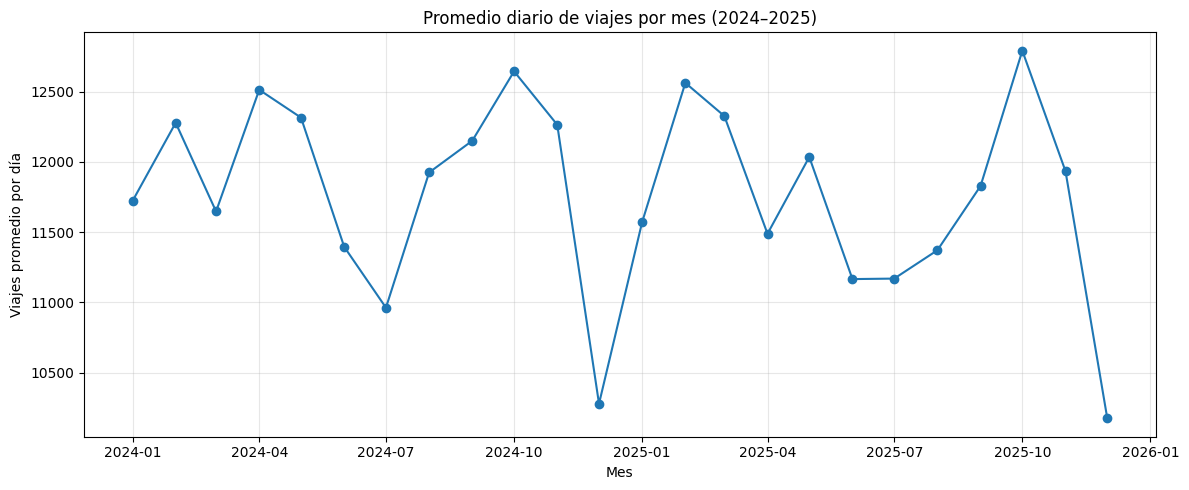

In [12]:

# Calcular viajes por día de cada mes
viajes_diarios_mes = (
    trips_limpios
    .assign(
        fecha=trips_limpios["Inicio_del_viaje"].dt.normalize(),
        mes=trips_limpios["Inicio_del_viaje"].dt.to_period("M")
    )
    .groupby(["mes", "fecha"])
    .size()
    .rename("viajes_dia")
    .reset_index()
)

# Resumir el promedio, mediana y variabilidad diaria de cada mes
resumen_mensual = (
    viajes_diarios_mes
    .groupby("mes")["viajes_dia"]
    .agg(["mean", "median", "std", "count"])
    .rename(columns={
        "mean": "promedio_diario",
        "median": "mediana_diaria",
        "std": "desviacion_estandar",
        "count": "dias_observados"
    })
)

display(resumen_mensual.round(2))

# Graficar el promedio diario mensual
plt.figure(figsize=(12, 5))
plt.plot(
    resumen_mensual.index.to_timestamp(),
    resumen_mensual["promedio_diario"],
    marker="o"
)
plt.title("Promedio diario de viajes por mes (2024–2025)")
plt.xlabel("Mes")
plt.ylabel("Viajes promedio por día")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [14]:

# Ordenar los días por menor volumen de viajes
dias_menor_volumen = (
    viajes_diarios
    .sort_values(ascending=True)
    .head(20)
    .rename("numero_viajes")
    .to_frame()
)

display(dias_menor_volumen)

# Resumen de los días con menor volumen
print("Mínimo diario:", viajes_diarios.min())
print("Mediana diaria:", viajes_diarios.median())
print("Percentil 1:", viajes_diarios.quantile(0.01))
print("Percentil 5:", viajes_diarios.quantile(0.05))


,numero_viajes
fecha,
2024-12-25,2586
2025-12-25,2832
2024-01-01,3102
2025-01-01,3149
2024-02-16,6017
2025-09-16,6226
2025-04-18,6394
2024-09-16,6431
2024-03-29,6491


Mínimo diario: 2586
Mediana diaria: 12927.0
Percentil 1: 6449.0
Percentil 5: 7391.0


In [15]:

nombres_dias = {
    "Monday": "Lunes",
    "Tuesday": "Martes",
    "Wednesday": "Miércoles",
    "Thursday": "Jueves",
    "Friday": "Viernes",
    "Saturday": "Sábado",
    "Sunday": "Domingo"
}

dias_menor_volumen["dia_semana"] = (
    pd.to_datetime(dias_menor_volumen.index)
    .day_name()
    .map(nombres_dias)
)

display(dias_menor_volumen)


,numero_viajes,dia_semana
fecha,,
2024-12-25,2586,Miércoles
2025-12-25,2832,Jueves
2024-01-01,3102,Lunes
2025-01-01,3149,Miércoles
2024-02-16,6017,Viernes
2025-09-16,6226,Martes
2025-04-18,6394,Viernes
2024-09-16,6431,Lunes
2024-03-29,6491,Viernes


In [17]:

# Crear una copia de la serie diaria y añadir atributos de calendario
analisis_diario = viajes_diarios.rename("numero_viajes").to_frame()

analisis_diario.index = pd.to_datetime(analisis_diario.index)
analisis_diario["dia_semana"] = analisis_diario.index.dayofweek
analisis_diario["mes"] = analisis_diario.index.month

# Promedio histórico del mismo día de la semana
promedio_por_dia = analisis_diario.groupby(
    "dia_semana"
)["numero_viajes"].transform("mean")

analisis_diario["promedio_dia_semana"] = promedio_por_dia

# Diferencia porcentual respecto al promedio de ese día
analisis_diario["variacion_pct"] = (
    (analisis_diario["numero_viajes"] /
     analisis_diario["promedio_dia_semana"]) - 1
) * 100

# Mostrar los 20 días más bajos con su comparación
display(
    analisis_diario
    .sort_values("numero_viajes")
    .head(20)
    .round(2)
)


,numero_viajes,dia_semana,mes,promedio_dia_semana,variacion_pct
fecha,,,,,
2024-12-25,2586,2,12,13476.98,-80.81
2025-12-25,2832,3,12,13377.45,-78.83
2024-01-01,3102,0,1,12513.37,-75.21
2025-01-01,3149,2,1,13476.98,-76.63
2024-02-16,6017,4,2,12686.92,-52.57
2025-09-16,6226,1,9,13495.46,-53.87
2025-04-18,6394,4,4,12686.92,-49.60
2024-09-16,6431,0,9,12513.37,-48.61
2024-03-29,6491,4,3,12686.92,-48.84


In [18]:

# Crear una copia de la serie diaria y añadir atributos de calendario
analisis_diario = viajes_diarios.rename("numero_viajes").to_frame()

analisis_diario.index = pd.to_datetime(analisis_diario.index)
analisis_diario["dia_semana"] = analisis_diario.index.dayofweek
analisis_diario["mes"] = analisis_diario.index.month

# Promedio histórico del mismo día de la semana
promedio_por_dia = analisis_diario.groupby(
    "dia_semana"
)["numero_viajes"].transform("mean")

analisis_diario["promedio_dia_semana"] = promedio_por_dia

# Diferencia porcentual respecto al promedio de ese día
analisis_diario["variacion_pct"] = (
    (analisis_diario["numero_viajes"] /
     analisis_diario["promedio_dia_semana"]) - 1
) * 100

# Mostrar los 20 días más bajos con su comparación
display(
    analisis_diario
    .sort_values("numero_viajes")
    .head(20)
    .round(2)
)


,numero_viajes,dia_semana,mes,promedio_dia_semana,variacion_pct
fecha,,,,,
2024-12-25,2586,2,12,13476.98,-80.81
2025-12-25,2832,3,12,13377.45,-78.83
2024-01-01,3102,0,1,12513.37,-75.21
2025-01-01,3149,2,1,13476.98,-76.63
2024-02-16,6017,4,2,12686.92,-52.57
2025-09-16,6226,1,9,13495.46,-53.87
2025-04-18,6394,4,4,12686.92,-49.60
2024-09-16,6431,0,9,12513.37,-48.61
2024-03-29,6491,4,3,12686.92,-48.84


### Hallazgos preliminares sobre la demanda diaria

El análisis de los viajes de MiBici durante 2024 y 2025 muestra diferencias importantes en la demanda según el día de la semana y el mes. Los martes presentan el mayor promedio diario de viajes, mientras que los domingos registran el menor. Asimismo, octubre concentra los mayores promedios diarios de ambos años y diciembre los menores.

También se identificaron caídas pronunciadas durante fechas como Navidad y Año Nuevo. Por ejemplo, el 25 de diciembre de 2024 se registraron 2,586 viajes, aproximadamente un 80.81% por debajo del promedio de los miércoles. Estos resultados sugieren que los patrones temporales deben considerarse al interpretar los datos, sin clasificar automáticamente estas fechas como anomalías.

Estos hallazgos constituyen una exploración inicial y no determinan por sí mismos las variables predictoras ni las etiquetas de riesgo del modelo de clasificación.


### Preparación de variables para la clasificación de riesgo

Para aproximar el riesgo operativo de las estaciones, se calcularán las llegadas y salidas de bicicletas por estación y hora. El flujo neto se definirá como la diferencia entre llegadas y salidas. Un flujo neto negativo representa una mayor salida de bicicletas, mientras que uno positivo representa una mayor llegada.

Estos indicadores describen el movimiento observado, no el inventario real disponible. En una etapa posterior se utilizarán para definir una variable objetivo de riesgo y construir predictores temporales que permitan estimar el riesgo de la siguiente hora, evitando utilizar información futura como entrada del modelo.


In [21]:
# Salidas: estación de origen y hora de inicio del viaje
salidas = (
    trips_limpios
    .assign(hora=trips_limpios["Inicio_del_viaje"].dt.floor("h"))
    .groupby(["Origen_Id", "hora"])
    .size()
    .rename("salidas")
    .reset_index()
    .rename(columns={"Origen_Id": "estacion_id"})
)

# Llegadas: estación de destino y hora de finalización del viaje
llegadas = (
    trips_limpios
    .assign(hora=trips_limpios["Fin_del_viaje"].dt.floor("h"))
    .groupby(["Destino_Id", "hora"])
    .size()
    .rename("llegadas")
    .reset_index()
    .rename(columns={"Destino_Id": "estacion_id"})
)

# Unir los dos flujos
flujo_horario = salidas.merge(
    llegadas,
    on=["estacion_id", "hora"],
    how="outer",
)

flujo_horario[["salidas", "llegadas"]] = (
    flujo_horario[["salidas", "llegadas"]]
    .fillna(0)
    .astype("int32")
)

# Flujo neto: positivo = más llegadas; negativo = más salidas
flujo_horario["flujo_neto"] = (
    flujo_horario["llegadas"] - flujo_horario["salidas"]
)

flujo_horario = flujo_horario.sort_values(
    ["estacion_id", "hora"]
).reset_index(drop=True)

print(f"Registros estación-hora: {len(flujo_horario):,}")
display(flujo_horario.head(10))

Registros estación-hora: 3,731,297


,estacion_id,hora,salidas,llegadas,flujo_neto
0,2,2024-01-01 07:00:00,0,1,1
1,2,2024-01-01 08:00:00,1,0,-1
2,2,2024-01-01 09:00:00,1,1,0
3,2,2024-01-01 10:00:00,2,0,-2
4,2,2024-01-01 12:00:00,2,0,-2
5,2,2024-01-01 13:00:00,3,2,-1
6,2,2024-01-01 14:00:00,2,1,-1
7,2,2024-01-01 15:00:00,1,2,1
8,2,2024-01-01 16:00:00,1,1,0
9,2,2024-01-01 17:00:00,0,1,1


In [22]:
print("Registros:", len(flujo_horario))
print("Estaciones:", flujo_horario["estacion_id"].nunique())
print("Horas distintas:", flujo_horario["hora"].nunique())

print("\nValores nulos:")
display(flujo_horario.isna().sum().to_frame("nulos"))

print("\nResumen de los movimientos:")
display(flujo_horario[["salidas", "llegadas", "flujo_neto"]].describe().round(2))

print("\nValidación del flujo neto:")
print(
    "¿Todos los flujos netos coinciden?",
    (
        flujo_horario["flujo_neto"]
        == flujo_horario["llegadas"] - flujo_horario["salidas"]
    ).all()
)

Registros: 3731297
Estaciones: 373
Horas distintas: 15439

Valores nulos:


,nulos
estacion_id,0
hora,0
salidas,0
llegadas,0
flujo_neto,0



Resumen de los movimientos:


,salidas,llegadas,flujo_neto
count,3731297.00,3731297.00,3731297.00
mean,2.31,2.31,0.00
std,2.81,3.04,2.59
min,0.00,0.00,-71.00
25%,1.00,1.00,-1.00
50%,1.00,1.00,0.00
75%,3.00,3.00,1.00
max,192.00,196.00,104.00



Validación del flujo neto:
¿Todos los flujos netos coinciden? True


In [24]:
# Calcular la diferencia entre registros consecutivos
flujo_horario["diferencia_horas"] = (
    flujo_horario.groupby("estacion_id")["hora"]
    .diff()
    .dt.total_seconds()
    .div(3600)
)

# Revisar la continuidad temporal
print("Diferencias entre registros consecutivos:")
display(
    flujo_horario["diferencia_horas"]
    .value_counts()
    .sort_index()
    .head(10)
)

print(
    "\nRegistros separados por más de una hora:",
    (flujo_horario["diferencia_horas"] > 1).sum()
)

Diferencias entre registros consecutivos:


diferencia_horas
1.0     3002376
2.0      311345
3.0       87902
4.0       36190
5.0       41067
6.0       56216
7.0       57594
8.0       45899
9.0       31837
10.0      20622
Name: count, dtype: int64


Registros separados por más de una hora: 728548


In [25]:
# Identificar si el registro anterior corresponde exactamente a una hora antes
flujo_horario["hora_anterior_valida"] = (
    flujo_horario["diferencia_horas"] == 1
)

# Invalidar los valores anteriores cuando hay un salto temporal
columnas_lag = [
    "salidas_hora_anterior",
    "llegadas_hora_anterior",
    "flujo_neto_hora_anterior",
]

flujo_horario.loc[
    ~flujo_horario["hora_anterior_valida"],
    columnas_lag
] = float("nan")

print("Registros totales:", len(flujo_horario))
print(
    "Registros con hora anterior válida:",
    flujo_horario["hora_anterior_valida"].sum()
)
print(
    "Registros sin hora anterior válida:",
    (~flujo_horario["hora_anterior_valida"]).sum()
)

display(
    flujo_horario.loc[
        flujo_horario["estacion_id"] == 2,
        [
            "estacion_id",
            "hora",
            "salidas",
            "llegadas",
            "flujo_neto",
            "diferencia_horas",
            "salidas_hora_anterior",
            "hora_anterior_valida",
        ],
    ].head(15)
)

Registros totales: 3731297
Registros con hora anterior válida: 3002376
Registros sin hora anterior válida: 728921


,estacion_id,hora,salidas,llegadas,flujo_neto,diferencia_horas,salidas_hora_anterior,hora_anterior_valida
0,2,2024-01-01 07:00:00,0,1,1,NaN,NaN,False
1,2,2024-01-01 08:00:00,1,0,-1,1.0,0.0,True
2,2,2024-01-01 09:00:00,1,1,0,1.0,1.0,True
3,2,2024-01-01 10:00:00,2,0,-2,1.0,1.0,True
4,2,2024-01-01 12:00:00,2,0,-2,2.0,NaN,False
5,2,2024-01-01 13:00:00,3,2,-1,1.0,2.0,True
6,2,2024-01-01 14:00:00,2,1,-1,1.0,3.0,True
7,2,2024-01-01 15:00:00,1,2,1,1.0,2.0,True
8,2,2024-01-01 16:00:00,1,1,0,1.0,1.0,True
9,2,2024-01-01 17:00:00,0,1,1,1.0,1.0,True


In [26]:
# Distribución del flujo neto
display(
    flujo_horario["flujo_neto"]
    .describe(percentiles=[0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
    .to_frame("flujo_neto")
    .round(2)
)

print("\nPorcentaje de registros por tipo de flujo:")

resumen_flujo = pd.Series({
    "Más salidas que llegadas": (flujo_horario["flujo_neto"] < 0).mean() * 100,
    "Flujo equilibrado": (flujo_horario["flujo_neto"] == 0).mean() * 100,
    "Más llegadas que salidas": (flujo_horario["flujo_neto"] > 0).mean() * 100,
})

display(resumen_flujo.round(2).to_frame("porcentaje"))

,flujo_neto
count,3731297.00
mean,0.00
std,2.59
min,-71.00
1%,-6.00
5%,-4.00
10%,-2.00
25%,-1.00
50%,0.00
75%,1.00



Porcentaje de registros por tipo de flujo:


,porcentaje
Más salidas que llegadas,42.17
Flujo equilibrado,16.60
Más llegadas que salidas,41.23


In [27]:
umbrales = [2, 4, 6, 10]

resumen_desequilibrios = pd.DataFrame({
    "umbral": umbrales,
    "salidas_exceden_llegadas": [
        (flujo_horario["flujo_neto"] <= -u).mean() * 100
        for u in umbrales
    ],
    "llegadas_exceden_salidas": [
        (flujo_horario["flujo_neto"] >= u).mean() * 100
        for u in umbrales
    ],
})

display(resumen_desequilibrios.round(2))

,umbral,salidas_exceden_llegadas,llegadas_exceden_salidas
0,2,19.75,19.38
1,4,5.23,5.23
2,6,1.64,1.70
3,10,0.24,0.32


### Análisis exploratorio del desequilibrio por hora del día

En esta sección se analiza cómo varía el balance entre llegadas y salidas de bicicletas según la hora del día. El objetivo es identificar patrones horarios de desequilibrio y determinar si existen periodos en los que las estaciones presentan una mayor concentración de salidas o llegadas. Estos resultados servirán como evidencia exploratoria para definir posteriormente el riesgo operativo, sin establecer todavía umbrales definitivos.

In [28]:
resumen_por_hora = (
    flujo_horario
    .groupby("hora_dia")
    .agg(
        registros=("flujo_neto", "size"),
        flujo_neto_promedio=("flujo_neto", "mean"),
        flujo_neto_mediano=("flujo_neto", "median"),
        desequilibrio_absoluto_promedio=(
            "flujo_neto",
            lambda x: x.abs().mean()
        ),
        porcentaje_desequilibrio_mayor_4=(
            "flujo_neto",
            lambda x: (x.abs() >= 4).mean() * 100
        )
    )
    .reset_index()
    .round(2)
)

resumen_por_hora

,hora_dia,registros,flujo_neto_promedio,flujo_neto_mediano,desequilibrio_absoluto_promedio,porcentaje_desequilibrio_mayor_4
0,0,67754,0.10,0.0,1.13,1.45
1,1,8336,1.09,1.0,1.10,0.08
2,2,87,1.01,1.0,1.01,0.00
3,3,10,1.20,1.0,1.20,0.00
4,5,77288,-0.22,-1.0,1.14,0.89
5,6,161107,-0.24,0.0,1.47,6.44
6,7,201391,-0.25,0.0,1.88,13.14
7,8,222974,-0.14,0.0,2.28,19.11
8,9,215230,0.25,0.0,1.79,11.81
9,10,202550,0.00,0.0,1.48,7.21


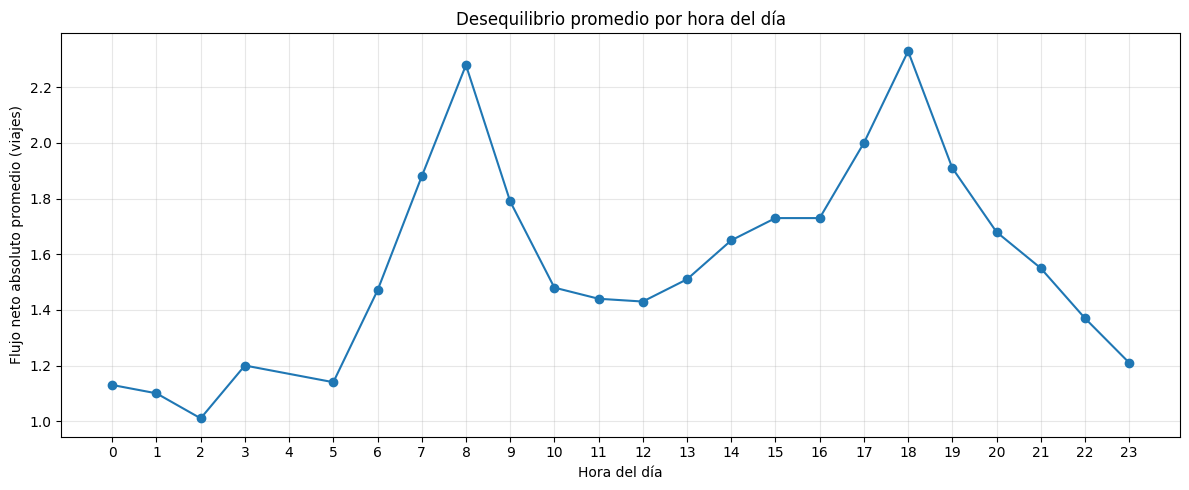

In [29]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    resumen_por_hora["hora_dia"],
    resumen_por_hora["desequilibrio_absoluto_promedio"],
    marker="o"
)

ax.set(
    title="Desequilibrio promedio por hora del día",
    xlabel="Hora del día",
    ylabel="Flujo neto absoluto promedio (viajes)"
)

ax.set_xticks(range(24))
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [30]:
resumen_por_estacion = (
    flujo_horario
    .groupby("estacion_id")
    .agg(
        registros=("flujo_neto", "size"),
        desequilibrio_absoluto_promedio=(
            "flujo_neto",
            lambda x: x.abs().mean()
        ),
        porcentaje_desequilibrio_mayor_4=(
            "flujo_neto",
            lambda x: (x.abs() >= 4).mean() * 100
        ),
        flujo_neto_promedio=("flujo_neto", "mean")
    )
    .reset_index()
    .sort_values(
        "desequilibrio_absoluto_promedio",
        ascending=False
    )
    .round(2)
)

resumen_por_estacion.head(15)

,estacion_id,registros,desequilibrio_absoluto_promedio,porcentaje_desequilibrio_mayor_4,flujo_neto_promedio
47,51,14214,11.22,60.59,3.68
31,35,13470,3.78,39.38,2.18
30,34,12337,3.44,31.41,1.90
8,11,14311,3.41,37.54,-0.62
175,194,12801,3.36,27.19,-2.21
48,52,14294,3.12,33.06,-0.22
61,65,13582,3.06,32.58,-0.13
38,42,13743,3.01,31.16,0.50
248,271,14067,2.95,31.73,-0.53
237,260,13468,2.91,27.47,1.79


In [31]:
resumen_por_estacion[
    [
        "estacion_id",
        "registros",
        "desequilibrio_absoluto_promedio",
        "porcentaje_desequilibrio_mayor_4",
        "flujo_neto_promedio",
    ]
].describe().round(2)

,estacion_id,registros,desequilibrio_absoluto_promedio,porcentaje_desequilibrio_mayor_4,flujo_neto_promedio
count,373.0,373.00,373.00,373.00,373.00
mean,203.73,10003.48,1.58,8.74,-0.03
std,116.72,3037.14,0.69,8.09,0.47
min,2.0,158.00,0.92,0.00,-2.21
25%,101.0,7994.00,1.18,2.33,-0.31
50%,205.0,10753.00,1.47,7.05,-0.09
75%,307.0,12447.00,1.79,12.85,0.18
max,402.0,14486.00,11.22,60.59,3.68


In [32]:
umbrales = [2, 4, 6, 10]

resumen_umbrales_estacion = pd.DataFrame({
    "umbral": umbrales,
    "mediana_porcentaje_estaciones": [
        (
            flujo_horario.groupby("estacion_id")["flujo_neto"]
            .apply(lambda x: (x.abs() >= u).mean() * 100)
            .median()
        )
        for u in umbrales
    ],
    "promedio_porcentaje_estaciones": [
        (
            flujo_horario.groupby("estacion_id")["flujo_neto"]
            .apply(lambda x: (x.abs() >= u).mean() * 100)
            .mean()
        )
        for u in umbrales
    ],
    "porcentaje_registros_global": [
        (flujo_horario["flujo_neto"].abs() >= u).mean() * 100
        for u in umbrales
    ]
}).round(2)

resumen_umbrales_estacion

,umbral,mediana_porcentaje_estaciones,promedio_porcentaje_estaciones,porcentaje_registros_global
0,2,37.22,35.71,39.13
1,4,7.05,8.74,10.47
2,6,1.17,2.68,3.34
3,10,0.02,0.43,0.56


In [33]:
resumen_horario_umbrales = (
    flujo_horario
    .groupby("hora_dia")
    .agg(
        registros=("flujo_neto", "size"),
        porcentaje_umbral_2=(
            "flujo_neto",
            lambda x: (x.abs() >= 2).mean() * 100
        ),
        porcentaje_umbral_4=(
            "flujo_neto",
            lambda x: (x.abs() >= 4).mean() * 100
        ),
        porcentaje_umbral_6=(
            "flujo_neto",
            lambda x: (x.abs() >= 6).mean() * 100
        )
    )
    .reset_index()
    .round(2)
)

resumen_horario_umbrales

,hora_dia,registros,porcentaje_umbral_2,porcentaje_umbral_4,porcentaje_umbral_6
0,0,67754,19.05,1.45,0.18
1,1,8336,8.72,0.08,0.00
2,2,87,1.15,0.00,0.00
3,3,10,10.00,0.00,0.00
4,5,77288,18.98,0.89,0.07
5,6,161107,33.56,6.44,1.60
6,7,201391,43.17,13.14,4.70
7,8,222974,50.12,19.11,8.03
8,9,215230,42.07,11.81,3.77
9,10,202550,35.46,7.21,1.80


In [34]:
resumen_direccion_horaria = (
    flujo_horario
    .groupby("hora_dia")
    .agg(
        registros=("flujo_neto", "size"),
        exceso_salidas_4=(
            "flujo_neto",
            lambda x: (x <= -4).mean() * 100
        ),
        exceso_llegadas_4=(
            "flujo_neto",
            lambda x: (x >= 4).mean() * 100
        ),
        exceso_salidas_6=(
            "flujo_neto",
            lambda x: (x <= -6).mean() * 100
        ),
        exceso_llegadas_6=(
            "flujo_neto",
            lambda x: (x >= 6).mean() * 100
        )
    )
    .reset_index()
    .round(2)
)

resumen_direccion_horaria

,hora_dia,registros,exceso_salidas_4,exceso_llegadas_4,exceso_salidas_6,exceso_llegadas_6
0,0,67754,1.06,0.40,0.16,0.02
1,1,8336,0.00,0.08,0.00,0.00
2,2,87,0.00,0.00,0.00,0.00
3,3,10,0.00,0.00,0.00,0.00
4,5,77288,0.38,0.51,0.02,0.05
5,6,161107,3.69,2.76,0.92,0.67
6,7,201391,7.08,6.06,2.50,2.20
7,8,222974,9.41,9.70,3.73,4.30
8,9,215230,4.05,7.76,1.06,2.71
9,10,202550,3.11,4.10,0.61,1.20


In [35]:
# Primera y última hora registrada por estación
cobertura_estaciones = (
    flujo_horario
    .groupby("estacion_id")
    .agg(
        primera_hora=("hora", "min"),
        ultima_hora=("hora", "max"),
        horas_con_registros=("hora", "nunique")
    )
    .reset_index()
)

# Horas que debería abarcar cada estación entre su primer
# y último registro, suponiendo una secuencia horaria continua.
cobertura_estaciones["horas_esperadas"] = (
    (
        cobertura_estaciones["ultima_hora"]
        - cobertura_estaciones["primera_hora"]
    ).dt.total_seconds() / 3600
).round().astype("int64") + 1

cobertura_estaciones["horas_sin_registro"] = (
    cobertura_estaciones["horas_esperadas"]
    - cobertura_estaciones["horas_con_registros"]
)

cobertura_estaciones["porcentaje_cobertura"] = (
    cobertura_estaciones["horas_con_registros"]
    / cobertura_estaciones["horas_esperadas"] * 100
).round(2)

cobertura_estaciones.sort_values(
    "porcentaje_cobertura"
).head(15)

,estacion_id,primera_hora,ultima_hora,horas_con_registros,horas_esperadas,horas_sin_registro,porcentaje_cobertura
96,104,2024-01-02 16:00:00,2024-06-06 20:00:00,537,3749,3212,14.32
328,356,2024-01-01 07:00:00,2025-12-31 18:00:00,2572,17532,14960,14.67
220,240,2024-01-01 13:00:00,2025-06-06 09:00:00,2276,12525,10249,18.17
351,380,2024-01-02 05:00:00,2025-12-31 23:00:00,3400,17515,14115,19.41
93,101,2024-01-02 07:00:00,2025-12-31 14:00:00,3497,17504,14007,19.98
201,220,2024-01-01 12:00:00,2025-12-31 19:00:00,3558,17528,13970,20.30
129,146,2024-01-01 16:00:00,2025-12-31 21:00:00,3597,17526,13929,20.52
282,310,2024-01-01 19:00:00,2024-06-06 19:00:00,798,3769,2971,21.17
120,136,2024-01-01 10:00:00,2025-12-31 21:00:00,4050,17532,13482,23.10
371,401,2025-10-09 18:00:00,2025-12-31 12:00:00,463,1987,1524,23.30


In [36]:
cobertura_estaciones[
    [
        "horas_con_registros",
        "horas_esperadas",
        "horas_sin_registro",
        "porcentaje_cobertura"
    ]
].describe().round(2)

,horas_con_registros,horas_esperadas,horas_sin_registro,porcentaje_cobertura
count,373.00,373.00,373.00,373.00
mean,10003.48,17096.27,7092.79,58.09
std,3037.14,2127.88,2797.58,16.04
min,158.00,630.00,472.00,14.32
25%,7994.00,17528.00,4858.00,47.85
50%,10753.00,17533.00,6432.00,61.76
75%,12447.00,17536.00,8988.00,71.02
max,14486.00,17545.00,14960.00,82.59


In [37]:
print(
    "Estaciones con cobertura menor al 25%:",
    (cobertura_estaciones["porcentaje_cobertura"] < 25).sum()
)

print(
    "Estaciones con cobertura menor al 50%:",
    (cobertura_estaciones["porcentaje_cobertura"] < 50).sum()
)

print(
    "Estaciones con cobertura mayor o igual al 75%:",
    (cobertura_estaciones["porcentaje_cobertura"] >= 75).sum()
)

Estaciones con cobertura menor al 25%: 10
Estaciones con cobertura menor al 50%: 106
Estaciones con cobertura mayor o igual al 75%: 50


In [38]:
# Diferencia temporal entre registros consecutivos por estación
intervalos = (
    flujo_horario
    .sort_values(["estacion_id", "hora"])
    .groupby("estacion_id")
    .agg(
        primera_hora=("hora", "min"),
        ultima_hora=("hora", "max"),
        horas_con_registros=("hora", "size")
    )
)

diferencias = (
    flujo_horario
    .sort_values(["estacion_id", "hora"])
    .groupby("estacion_id")["hora"]
    .diff()
    .dt.total_seconds()
    .div(3600)
    .dropna()
)

resumen_intervalos = pd.Series({
    "intervalos_analizados": len(diferencias),
    "separacion_1_hora_pct": (diferencias == 1).mean() * 100,
    "separacion_mayor_1_hora_pct": (diferencias > 1).mean() * 100,
    "separacion_mayor_24_horas_pct": (diferencias > 24).mean() * 100,
    "separacion_mayor_168_horas_pct": (diferencias > 168).mean() * 100,
})

resumen_intervalos.round(2)

intervalos_analizados             3730924.00
separacion_1_hora_pct                  80.47
separacion_mayor_1_hora_pct            19.53
separacion_mayor_24_horas_pct           0.02
separacion_mayor_168_horas_pct          0.00
dtype: float64

In [39]:
continuidad_estacion = (
    flujo_horario
    .sort_values(["estacion_id", "hora"])
    .groupby("estacion_id")["hora"]
    .apply(
        lambda x: (
            x.diff().dt.total_seconds().div(3600) == 1
        ).mean() * 100
    )
    .rename("porcentaje_intervalos_1_hora")
    .reset_index()
)

continuidad_estacion[
    "porcentaje_intervalos_1_hora"
].describe().round(2)

count    373.00
mean      75.81
std       16.34
min       27.90
25%       66.61
50%       81.07
75%       89.03
max       94.56
Name: porcentaje_intervalos_1_hora, dtype: float64

In [40]:
def clasificar_desequilibrio(flujo):
    if -3 <= flujo <= 3:
        return "bajo"
    elif -5 <= flujo <= -4 or 4 <= flujo <= 5:
        return "medio"
    else:
        return "alto"


flujo_horario["riesgo_provisional"] = (
    flujo_horario["flujo_neto"]
    .apply(clasificar_desequilibrio)
)

resumen_riesgo = (
    flujo_horario["riesgo_provisional"]
    .value_counts()
    .rename_axis("riesgo")
    .to_frame("registros")
)

resumen_riesgo["porcentaje"] = (
    resumen_riesgo["registros"]
    / len(flujo_horario) * 100
).round(2)

resumen_riesgo

,registros,porcentaje
riesgo,,
bajo,3340792,89.53
medio,265744,7.12
alto,124761,3.34


In [41]:
resumen_riesgo_estacion = (
    flujo_horario
    .groupby(["estacion_id", "riesgo_provisional"])
    .size()
    .unstack(fill_value=0)
)

for clase in ["bajo", "medio", "alto"]:
    if clase not in resumen_riesgo_estacion.columns:
        resumen_riesgo_estacion[clase] = 0

resumen_riesgo_estacion["total"] = (
    resumen_riesgo_estacion[["bajo", "medio", "alto"]].sum(axis=1)
)

for clase in ["bajo", "medio", "alto"]:
    resumen_riesgo_estacion[f"porcentaje_{clase}"] = (
        resumen_riesgo_estacion[clase]
        / resumen_riesgo_estacion["total"] * 100
    )

resumen_riesgo_estacion.sort_values(
    "porcentaje_alto", ascending=False
).head(15).round(2)

riesgo_provisional,alto,bajo,medio,total,porcentaje_bajo,porcentaje_medio,porcentaje_alto
estacion_id,,,,,,,
51,7011,5602,1601,14214,39.41,11.26,49.32
35,3294,8165,2011,13470,60.62,14.93,24.45
11,2886,8939,2486,14311,62.46,17.37,20.17
34,2239,8462,1636,12337,68.59,13.26,18.15
65,2391,9157,2034,13582,67.42,14.98,17.60
52,2407,9568,2319,14294,66.94,16.22,16.84
271,2187,9604,2276,14067,68.27,16.18,15.55
42,2108,9461,2174,13743,68.84,15.82,15.34
38,2100,9710,1994,13804,70.34,14.45,15.21


In [42]:
resumen_direccion_estacion = (
    flujo_horario
    .groupby("estacion_id")
    .agg(
        registros=("flujo_neto", "size"),
        exceso_salidas=("flujo_neto", lambda x: (x <= -6).mean() * 100),
        exceso_llegadas=("flujo_neto", lambda x: (x >= 6).mean() * 100),
        flujo_neto_promedio=("flujo_neto", "mean"),
        desequilibrio_absoluto_promedio=("flujo_neto", lambda x: x.abs().mean())
    )
    .reset_index()
)

resumen_direccion_estacion.sort_values(
    "desequilibrio_absoluto_promedio",
    ascending=False
).head(15).round(2)

,estacion_id,registros,exceso_salidas,exceso_llegadas,flujo_neto_promedio,desequilibrio_absoluto_promedio
47,51,14214,18.48,30.84,3.68,11.22
31,35,13470,3.67,20.78,2.18,3.78
30,34,12337,2.69,15.46,1.90,3.44
8,11,14311,12.45,7.71,-0.62,3.41
175,194,12801,12.72,2.14,-2.21,3.36
48,52,14294,9.77,7.07,-0.22,3.12
61,65,13582,8.93,8.67,-0.13,3.06
38,42,13743,6.02,9.31,0.50,3.01
248,271,14067,9.55,6.00,-0.53,2.95
237,260,13468,0.99,13.90,1.79,2.91


In [43]:
# Crear una copia de trabajo para preparar el conjunto de clasificación
datos_p2 = flujo_horario.copy()

# Variables temporales
datos_p2["dia_semana"] = datos_p2["hora"].dt.dayofweek
datos_p2["mes"] = datos_p2["hora"].dt.month
datos_p2["hora_sin"] = np.sin(
    2 * np.pi * datos_p2["hora_dia"] / 24
)
datos_p2["hora_cos"] = np.cos(
    2 * np.pi * datos_p2["hora_dia"] / 24
)

# Variables históricas: usar únicamente la hora anterior válida
datos_p2["flujo_neto_anterior"] = (
    datos_p2["flujo_neto_hora_anterior"]
)

datos_p2["salidas_anterior"] = (
    datos_p2["salidas_hora_anterior"]
)

datos_p2["llegadas_anterior"] = (
    datos_p2["llegadas_hora_anterior"]
)

# Revisar estructura
datos_p2[
    [
        "estacion_id",
        "hora",
        "dia_semana",
        "mes",
        "hora_sin",
        "hora_cos",
        "flujo_neto_anterior",
        "salidas_anterior",
        "llegadas_anterior",
        "riesgo_provisional"
    ]
].head(10)

,estacion_id,hora,dia_semana,mes,hora_sin,hora_cos,flujo_neto_anterior,salidas_anterior,llegadas_anterior,riesgo_provisional
0,2,2024-01-01 07:00:00,0,1,9.659258e-01,-0.258819,NaN,NaN,NaN,bajo
1,2,2024-01-01 08:00:00,0,1,8.660254e-01,-0.500000,1.0,0.0,1.0,bajo
2,2,2024-01-01 09:00:00,0,1,7.071068e-01,-0.707107,-1.0,1.0,0.0,bajo
3,2,2024-01-01 10:00:00,0,1,5.000000e-01,-0.866025,0.0,1.0,1.0,bajo
4,2,2024-01-01 12:00:00,0,1,1.224647e-16,-1.000000,NaN,NaN,NaN,bajo
5,2,2024-01-01 13:00:00,0,1,-2.588190e-01,-0.965926,-2.0,2.0,0.0,bajo
6,2,2024-01-01 14:00:00,0,1,-5.000000e-01,-0.866025,-1.0,3.0,2.0,bajo
7,2,2024-01-01 15:00:00,0,1,-7.071068e-01,-0.707107,-1.0,2.0,1.0,bajo
8,2,2024-01-01 16:00:00,0,1,-8.660254e-01,-0.500000,1.0,1.0,2.0,bajo
9,2,2024-01-01 17:00:00,0,1,-9.659258e-01,-0.258819,0.0,1.0,1.0,bajo


In [44]:
columnas_predictoras = [
    "dia_semana",
    "mes",
    "hora_sin",
    "hora_cos",
    "flujo_neto_anterior",
    "salidas_anterior",
    "llegadas_anterior",
]

resumen_variables = pd.DataFrame({
    "valores_nulos": datos_p2[columnas_predictoras].isna().sum(),
    "porcentaje_nulos": (
        datos_p2[columnas_predictoras].isna().mean() * 100
    ).round(2),
})

resumen_variables

,valores_nulos,porcentaje_nulos
dia_semana,0,0.00
mes,0,0.00
hora_sin,0,0.00
hora_cos,0,0.00
flujo_neto_anterior,728921,19.54
salidas_anterior,728921,19.54
llegadas_anterior,728921,19.54


### Preparación de la variable objetivo futura

Para formular el problema como una tarea de clasificación predictiva, se define como variable objetivo el nivel de desequilibrio observado en la siguiente hora de cada estación. Las variables predictoras deberán contener exclusivamente información disponible en el momento de realizar la predicción. Se conservará la continuidad temporal como criterio de validación, evitando asignar etiquetas futuras cuando no exista una observación exactamente una hora después.

In [45]:
# Ordenar cronológicamente los registros de cada estación
datos_p2 = (
    datos_p2
    .sort_values(["estacion_id", "hora"])
    .reset_index(drop=True)
)

# Obtener la hora y el riesgo de la siguiente observación
datos_p2["hora_siguiente"] = (
    datos_p2.groupby("estacion_id")["hora"].shift(-1)
)

datos_p2["riesgo_siguiente"] = (
    datos_p2.groupby("estacion_id")["riesgo_provisional"].shift(-1)
)

# Calcular la separación entre la hora actual y la siguiente
datos_p2["diferencia_horas_siguiente"] = (
    datos_p2["hora_siguiente"] - datos_p2["hora"]
).dt.total_seconds() / 3600

# Solo aceptar etiquetas si la siguiente observación es exactamente una hora después
datos_p2.loc[
    datos_p2["diferencia_horas_siguiente"] != 1,
    "riesgo_siguiente"
] = np.nan

# Revisar las primeras observaciones
datos_p2[
    [
        "estacion_id",
        "hora",
        "riesgo_provisional",
        "hora_siguiente",
        "diferencia_horas_siguiente",
        "riesgo_siguiente"
    ]
].head(15)

,estacion_id,hora,riesgo_provisional,hora_siguiente,diferencia_horas_siguiente,riesgo_siguiente
0,2,2024-01-01 07:00:00,bajo,2024-01-01 08:00:00,1.0,bajo
1,2,2024-01-01 08:00:00,bajo,2024-01-01 09:00:00,1.0,bajo
2,2,2024-01-01 09:00:00,bajo,2024-01-01 10:00:00,1.0,bajo
3,2,2024-01-01 10:00:00,bajo,2024-01-01 12:00:00,2.0,NaN
4,2,2024-01-01 12:00:00,bajo,2024-01-01 13:00:00,1.0,bajo
5,2,2024-01-01 13:00:00,bajo,2024-01-01 14:00:00,1.0,bajo
6,2,2024-01-01 14:00:00,bajo,2024-01-01 15:00:00,1.0,bajo
7,2,2024-01-01 15:00:00,bajo,2024-01-01 16:00:00,1.0,bajo
8,2,2024-01-01 16:00:00,bajo,2024-01-01 17:00:00,1.0,bajo
9,2,2024-01-01 17:00:00,bajo,2024-01-01 18:00:00,1.0,bajo


In [46]:
print("Total de registros:", len(datos_p2))

print(
    "Registros con etiqueta futura válida:",
    datos_p2["riesgo_siguiente"].notna().sum()
)

print(
    "Registros sin etiqueta futura válida:",
    datos_p2["riesgo_siguiente"].isna().sum()
)

print("\nDistribución de la etiqueta futura:")
print(
    datos_p2["riesgo_siguiente"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Total de registros: 3731297
Registros con etiqueta futura válida: 3002376
Registros sin etiqueta futura válida: 728921

Distribución de la etiqueta futura:
riesgo_siguiente
bajo     87.57
medio     8.36
alto      4.07
Name: proportion, dtype: float64


### Definición de los periodos de entrenamiento y evaluación

Para evaluar el modelo de clasificación se utilizará una separación temporal, de modo que los datos de entrenamiento correspondan a fechas anteriores a los de validación y prueba. Este procedimiento busca reproducir el escenario operativo de utilizar información histórica para anticipar el desequilibrio de una estación durante la siguiente hora. Los registros sin una etiqueta futura válida se excluirán de la evaluación supervisada.

In [47]:
# Revisar el rango temporal de los registros con etiqueta futura válida
datos_con_objetivo = datos_p2[
    datos_p2["riesgo_siguiente"].notna()
].copy()

print("Primera hora:", datos_con_objetivo["hora"].min())
print("Última hora:", datos_con_objetivo["hora"].max())

print("\nRegistros por año:")
print(datos_con_objetivo["hora"].dt.year.value_counts().sort_index())

print("\nRegistros por mes:")
print(
    datos_con_objetivo.groupby(
        datos_con_objetivo["hora"].dt.to_period("M")
    ).size()
)

Primera hora: 2024-01-01 00:00:00
Última hora: 2025-12-31 23:00:00

Registros por año:
hora
2024    1500028
2025    1502348
Name: count, dtype: int64

Registros por mes:
hora
2024-01    124120
2024-02    118757
2024-03    124885
2024-04    126256
2024-05    130908
2024-06    122261
2024-07    123749
2024-08    128194
2024-09    125078
2024-10    131025
2024-11    125810
2024-12    118985
2025-01    126576
2025-02    118604
2025-03    129440
2025-04    123164
2025-05    130597
2025-06    120864
2025-07    126217
2025-08    126350
2025-09    124902
2025-10    133565
2025-11    123694
2025-12    118375
Freq: M, dtype: int64


In [48]:
# Separación cronológica de los datos con objetivo válido
train_df = datos_con_objetivo[
    datos_con_objetivo["hora"] < "2025-07-01"
].copy()

valid_df = datos_con_objetivo[
    (datos_con_objetivo["hora"] >= "2025-07-01") &
    (datos_con_objetivo["hora"] < "2025-10-01")
].copy()

test_df = datos_con_objetivo[
    datos_con_objetivo["hora"] >= "2025-10-01"
].copy()

# Resumen de los conjuntos
resumen_particiones = pd.DataFrame({
    "conjunto": ["Entrenamiento", "Validación", "Prueba"],
    "registros": [len(train_df), len(valid_df), len(test_df)],
    "primera_hora": [
        train_df["hora"].min(),
        valid_df["hora"].min(),
        test_df["hora"].min()
    ],
    "ultima_hora": [
        train_df["hora"].max(),
        valid_df["hora"].max(),
        test_df["hora"].max()
    ]
})

resumen_particiones

,conjunto,registros,primera_hora,ultima_hora
0,Entrenamiento,2249273,2024-01-01 00:00:00,2025-06-30 23:00:00
1,Validación,377469,2025-07-01 05:00:00,2025-09-30 23:00:00
2,Prueba,375634,2025-10-01 00:00:00,2025-12-31 23:00:00


In [49]:
for nombre, conjunto in [
    ("Entrenamiento", train_df),
    ("Validación", valid_df),
    ("Prueba", test_df)
]:
    print(f"\n--- {nombre} ---")

    distribucion = (
        conjunto["riesgo_siguiente"]
        .value_counts()
        .reindex(["bajo", "medio", "alto"], fill_value=0)
        .to_frame("registros")
    )

    distribucion["porcentaje"] = (
        distribucion["registros"] / len(conjunto) * 100
    ).round(2)

    print(distribucion)


--- Entrenamiento ---
                  registros  porcentaje
riesgo_siguiente                       
bajo                1964056       87.32
medio                191094        8.50
alto                  94123        4.18

--- Validación ---
                  registros  porcentaje
riesgo_siguiente                       
bajo                 332506       88.09
medio                 30578        8.10
alto                  14385        3.81

--- Prueba ---
                  registros  porcentaje
riesgo_siguiente                       
bajo                 332740       88.58
medio                 29245        7.79
alto                  13649        3.63


In [50]:
# Variables predictoras disponibles al momento de la predicción
FEATURES = [
    "dia_semana",
    "mes",
    "hora_sin",
    "hora_cos",
    "flujo_neto_anterior",
    "salidas_anterior",
    "llegadas_anterior",
]

TARGET = "riesgo_siguiente"

print("Variables predictoras:")
print(FEATURES)

print("\nVariable objetivo:")
print(TARGET)

Variables predictoras:
['dia_semana', 'mes', 'hora_sin', 'hora_cos', 'flujo_neto_anterior', 'salidas_anterior', 'llegadas_anterior']

Variable objetivo:
riesgo_siguiente


In [51]:
for nombre, conjunto in [
    ("Entrenamiento", train_df),
    ("Validación", valid_df),
    ("Prueba", test_df)
]:
    nulos = conjunto[FEATURES].isna().any(axis=1).sum()
    completos = len(conjunto) - nulos

    print(f"\n--- {nombre} ---")
    print(f"Registros totales: {len(conjunto):,}")
    print(f"Registros con variables completas: {completos:,}")
    print(f"Registros con variables incompletas: {nulos:,}")
    print(f"Porcentaje completo: {completos / len(conjunto) * 100:.2f}%")


--- Entrenamiento ---
Registros totales: 2,249,273
Registros con variables completas: 1,898,168
Registros con variables incompletas: 351,105
Porcentaje completo: 84.39%

--- Validación ---
Registros totales: 377,469
Registros con variables completas: 316,712
Registros con variables incompletas: 60,757
Porcentaje completo: 83.90%

--- Prueba ---
Registros totales: 375,634
Registros con variables completas: 315,366
Registros con variables incompletas: 60,268
Porcentaje completo: 83.96%


In [52]:
# Filtrar registros con variables predictoras completas
train_model = train_df.dropna(subset=FEATURES + [TARGET]).copy()
valid_model = valid_df.dropna(subset=FEATURES + [TARGET]).copy()
test_model = test_df.dropna(subset=FEATURES + [TARGET]).copy()

# Separar variables predictoras y objetivo
X_train = train_model[FEATURES]
y_train = train_model[TARGET]

X_valid = valid_model[FEATURES]
y_valid = valid_model[TARGET]

X_test = test_model[FEATURES]
y_test = test_model[TARGET]

# Verificar dimensiones
print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_valid:", X_valid.shape, "| y_valid:", y_valid.shape)
print("X_test: ", X_test.shape,  "| y_test: ", y_test.shape)

X_train: (1898168, 7) | y_train: (1898168,)
X_valid: (316712, 7) | y_valid: (316712,)
X_test:  (315366, 7) | y_test:  (315366,)


In [53]:
for nombre, y in [
    ("Entrenamiento", y_train),
    ("Validación", y_valid),
    ("Prueba", y_test)
]:
    print(f"\n{nombre}")
    print(
        y.value_counts()
        .reindex(["bajo", "medio", "alto"], fill_value=0)
        .to_frame("registros")
        .assign(porcentaje=lambda df: (
            df["registros"] / len(y) * 100
        ).round(2))
    )


Entrenamiento
                  registros  porcentaje
riesgo_siguiente                       
bajo                1637780       86.28
medio                172730        9.10
alto                  87658        4.62

Validación
                  registros  porcentaje
riesgo_siguiente                       
bajo                 275746       87.07
medio                 27598        8.71
alto                  13368        4.22

Prueba
                  registros  porcentaje
riesgo_siguiente                       
bajo                 275996       87.52
medio                 26637        8.45
alto                  12733        4.04


In [54]:
from pathlib import Path

DATA_PROCESSED = ROOT / "data" / "processed"
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)

train_model.to_parquet(DATA_PROCESSED / "p2_train.parquet", index=False)
valid_model.to_parquet(DATA_PROCESSED / "p2_valid.parquet", index=False)
test_model.to_parquet(DATA_PROCESSED / "p2_test.parquet", index=False)

print("Conjuntos preparados guardados correctamente.")

Conjuntos preparados guardados correctamente.


## Conclusiones de la preparación de datos para P2

Se construyó un conjunto de datos horario por estación para analizar los desequilibrios entre las salidas y las llegadas de bicicletas. A partir del flujo neto observado, se definieron tres clases provisionales: bajo, medio y alto. Estas categorías representan niveles de desequilibrio y no deben interpretarse todavía como una medición validada del riesgo operativo real, ya que no se dispone de información directa sobre el inventario de bicicletas de cada estación.

Para plantear la clasificación, se definió como objetivo la clase de desequilibrio de la siguiente hora observada, siempre que exista continuidad horaria. Se estableció una separación temporal de los datos: entrenamiento de enero de 2024 a junio de 2025, validación de julio a septiembre de 2025 y prueba de octubre a diciembre de 2025. Se conservaron únicamente los registros con objetivo y variables predictoras completas.

Los conjuntos resultantes contienen 1,898,168 registros de entrenamiento, 316,712 de validación y 315,366 de prueba, cada uno con siete variables predictoras. Las clases presentan un desbalance importante, por lo que la evaluación posterior deberá considerar métricas como *recall*, F1 por clase y F1 macro, además de la matriz de confusión.

Finalmente, la predicción está condicionada a las horas con registros observados y a la disponibilidad de las variables anteriores. Los periodos sin registros no se interpretan automáticamente como horas sin actividad. Estas limitaciones deberán considerarse al evaluar los resultados y al valorar su posible aplicación operativa.